# 03 — Experimentos, MLflow y modelo final

Este notebook **no entrena nada**: lee lo que el pipeline ya registró en MLflow.
Esa separación es deliberada —el entrenamiento vive en código versionado y
orquestado (`src/pipelines/training_flow.py`), no en un notebook— y el notebook
sirve para analizar e interpretar los resultados.

Requisito: haber ejecutado al menos una vez

```bash
uv run python -m src.pipelines.training_flow
```

In [1]:
# Permite importar `src` ejecutando el notebook desde `notebooks/`.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

from src.config import load_config

config = load_config()
print(f"Proyecto: {config.project.name}")
print(f"Raíz:     {PROJECT_ROOT}")


Proyecto: bank-term-deposit-mlops
Raíz:     C:\Users\gjaim\OneDrive - The University of Melbourne\Documents\MLOPS 2026\Project\bank-term-deposit-mlops


In [2]:
import mlflow
from mlflow import MlflowClient

# `config.mlflow_tracking_uri` resuelve la ruta de SQLite contra la raíz del
# proyecto. Sin eso, ejecutar desde `notebooks/` apuntaría a otra base vacía.
mlflow.set_tracking_uri(config.mlflow_tracking_uri)
client = MlflowClient()

experiment = client.get_experiment_by_name(config.mlflow.experiment_name)
if experiment is None:
    raise RuntimeError(
        "No hay experimentos. Ejecuta: uv run python -m src.pipelines.training_flow"
    )

print(f"Experimento: {experiment.name} (id={experiment.experiment_id})")
print(f"Tracking:    {config.mlflow_tracking_uri}")

Experimento: bank-term-deposit (id=1)
Tracking:    sqlite:///C:/Users/gjaim/OneDrive - The University of Melbourne/Documents/MLOPS 2026/Project/bank-term-deposit-mlops/mlflow.db


## 1. Todos los runs registrados

In [3]:
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.valid_pr_auc DESC"],
)
print(f"Runs registrados: {len(runs)}")

# Solo los runs de primer nivel: se excluyen los trials anidados de Optuna.
top_level = runs[runs["tags.mlflow.parentRunId"].isna()] if "tags.mlflow.parentRunId" in runs else runs

summary = top_level[
    [
        "tags.mlflow.runName",
        "metrics.valid_pr_auc",
        "metrics.valid_roc_auc",
        "metrics.cv_pr_auc_mean",
        "metrics.cv_pr_auc_std",
        "metrics.valid_profit_usd",
    ]
].rename(
    columns={
        "tags.mlflow.runName": "run",
        "metrics.valid_pr_auc": "valid PR-AUC",
        "metrics.valid_roc_auc": "valid ROC-AUC",
        "metrics.cv_pr_auc_mean": "CV PR-AUC",
        "metrics.cv_pr_auc_std": "CV std",
        "metrics.valid_profit_usd": "utilidad USD",
    }
)
display(summary.dropna(subset=["valid PR-AUC"]).round(4).reset_index(drop=True))

Runs registrados: 26


,run,valid PR-AUC,valid ROC-AUC,CV PR-AUC,CV std,utilidad USD
0,xgboost_tuned,0.4707,0.8038,0.4676,0.0326,25152.0
1,random_forest,0.4655,0.8056,0.4620,0.0296,28888.0
2,xgboost,0.4600,0.7977,0.4435,0.0267,29904.0
3,logistic_regression,0.4417,0.7971,0.4444,0.0272,25272.0
4,baseline_majority,0.1126,0.5000,NaN,NaN,0.0


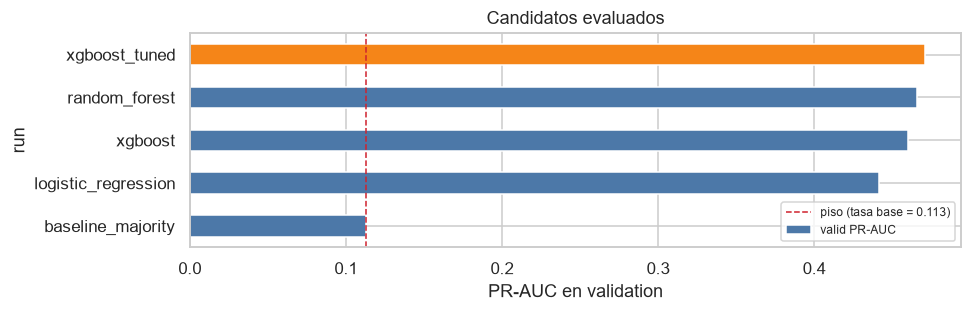

In [4]:
# El ranking, visualmente.
plot_data = (
    summary.dropna(subset=["valid PR-AUC"])
    .set_index("run")["valid PR-AUC"]
    .sort_values()
)

# El piso: PR-AUC de un modelo sin información = tasa base de positivos.
base_rate = float(top_level["params.train_positive_rate"].dropna().iloc[0])

fig, ax = plt.subplots(figsize=(9, max(3, 0.45 * len(plot_data))))
colors = ["#f58518" if value == plot_data.max() else "#4c78a8" for value in plot_data]
plot_data.plot.barh(ax=ax, color=colors)
ax.axvline(base_rate, color="#cf222e", linestyle="--", linewidth=1,
           label=f"piso (tasa base = {base_rate:.3f})")
ax.set_xlabel("PR-AUC en validation")
ax.set_title("Candidatos evaluados")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Cross-validation: ¿el resultado es estable o fue suerte?

Un PR-AUC alto en un solo split de validation puede ser ruido. La CV
estratificada de 5 folds sobre train muestra la dispersión real.

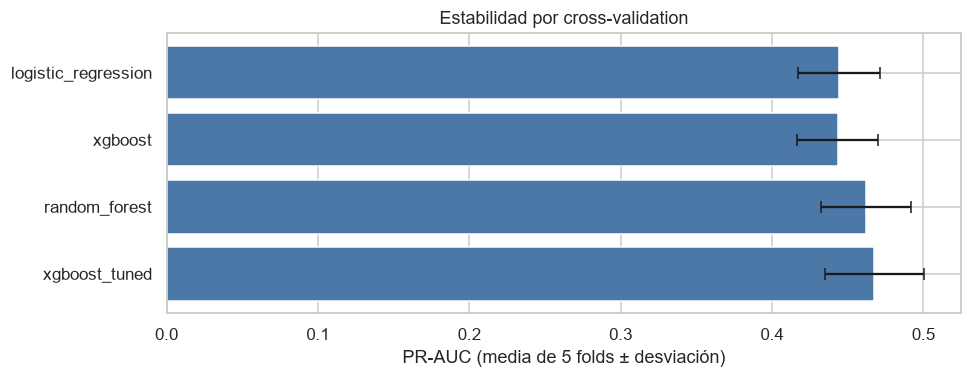

,CV PR-AUC,CV std,valid PR-AUC
run,,,
xgboost_tuned,0.4676,0.0326,0.4707
random_forest,0.4620,0.0296,0.4655
xgboost,0.4435,0.0267,0.4600
logistic_regression,0.4444,0.0272,0.4417



La diferencia entre 'CV PR-AUC' y 'valid PR-AUC' indica cuánto confiar
en el split de validation: si son cercanos, el resultado es estable.


In [5]:
cv_data = summary.dropna(subset=["CV PR-AUC"]).set_index("run")

if len(cv_data):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.barh(cv_data.index, cv_data["CV PR-AUC"], xerr=cv_data["CV std"],
            color="#4c78a8", capsize=4)
    ax.set_xlabel("PR-AUC (media de 5 folds ± desviación)")
    ax.set_title("Estabilidad por cross-validation")
    plt.tight_layout()
    plt.show()

    display(cv_data[["CV PR-AUC", "CV std", "valid PR-AUC"]].round(4))
    print()
    print("La diferencia entre 'CV PR-AUC' y 'valid PR-AUC' indica cuánto confiar")
    print("en el split de validation: si son cercanos, el resultado es estable.")
else:
    print("No hay métricas de CV registradas.")

## 3. La búsqueda de hiperparámetros con Optuna

Trials ejecutados: 20
Mejor PR-AUC:      0.4707
Peor PR-AUC:       0.4045
Rango explorado:   0.0662


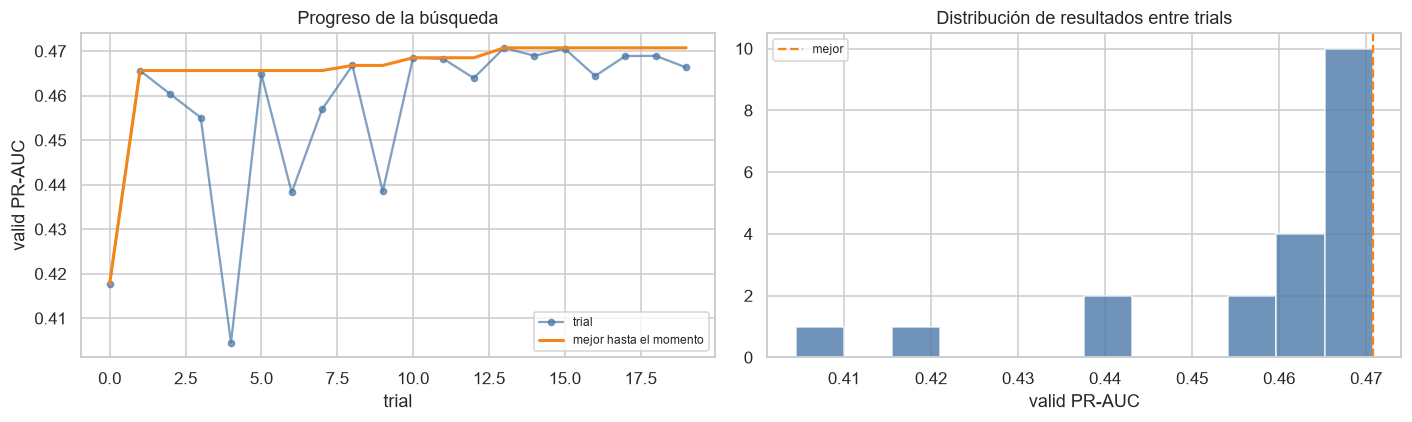

In [6]:
search_runs = runs[runs["tags.mlflow.runName"] == "xgboost-optuna-search"] if "tags.mlflow.runName" in runs else pd.DataFrame()

if len(search_runs):
    parent_id = search_runs.iloc[0]["run_id"]
    trials = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string=f"tags.mlflow.parentRunId = '{parent_id}'",
    )
    trials = trials.dropna(subset=["metrics.valid_pr_auc"]).copy()
    trials["trial"] = trials["tags.mlflow.runName"].str.extract(r"(\d+)").astype(int)
    trials = trials.sort_values("trial")

    print(f"Trials ejecutados: {len(trials)}")
    print(f"Mejor PR-AUC:      {trials['metrics.valid_pr_auc'].max():.4f}")
    print(f"Peor PR-AUC:       {trials['metrics.valid_pr_auc'].min():.4f}")
    print(f"Rango explorado:   {trials['metrics.valid_pr_auc'].max() - trials['metrics.valid_pr_auc'].min():.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(trials["trial"], trials["metrics.valid_pr_auc"], marker="o",
                 markersize=4, color="#4c78a8", alpha=0.7, label="trial")
    axes[0].plot(trials["trial"], trials["metrics.valid_pr_auc"].cummax(),
                 color="#f58518", linewidth=2, label="mejor hasta el momento")
    axes[0].set_xlabel("trial")
    axes[0].set_ylabel("valid PR-AUC")
    axes[0].set_title("Progreso de la búsqueda")
    axes[0].legend(fontsize=8)

    axes[1].hist(trials["metrics.valid_pr_auc"], bins=12, color="#4c78a8", alpha=0.8)
    axes[1].axvline(trials["metrics.valid_pr_auc"].max(), color="#f58518",
                    linestyle="--", label="mejor")
    axes[1].set_xlabel("valid PR-AUC")
    axes[1].set_title("Distribución de resultados entre trials")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    trials = pd.DataFrame()
    print("No hay búsqueda de Optuna registrada (¿se ejecutó con skip_tuning=True?).")

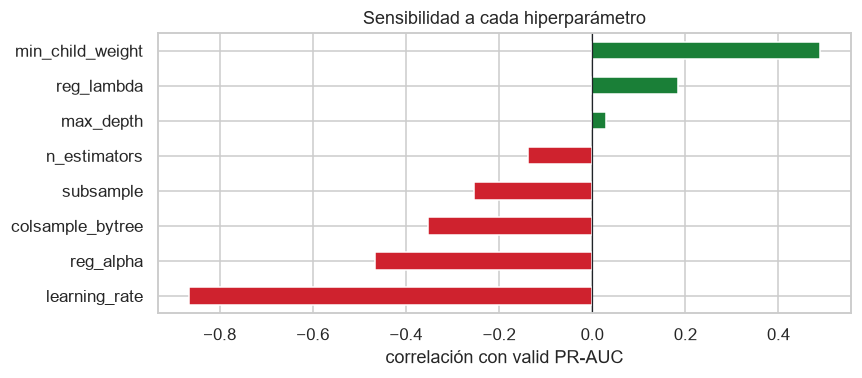

Advertencia: con ~20 trials estas correlaciones son indicativas,
no concluyentes. Sirven para orientar la próxima búsqueda.


In [7]:
# ¿Qué hiperparámetros movieron la aguja?
if len(trials):
    param_columns = [c for c in trials.columns if c.startswith("params.")
                     and trials[c].notna().all()]
    numeric_params = {}
    for column in param_columns:
        try:
            numeric_params[column.replace("params.", "")] = trials[column].astype(float)
        except (ValueError, TypeError):
            continue

    if numeric_params:
        param_frame = pd.DataFrame(numeric_params)
        correlations = param_frame.corrwith(trials["metrics.valid_pr_auc"].reset_index(drop=True)
                                            if param_frame.index.equals(pd.RangeIndex(len(param_frame)))
                                            else trials["metrics.valid_pr_auc"])
        correlations = correlations.dropna().sort_values()

        fig, ax = plt.subplots(figsize=(8, 3.6))
        colors = ["#cf222e" if v < 0 else "#1a7f37" for v in correlations]
        correlations.plot.barh(ax=ax, color=colors)
        ax.axvline(0, color="#1f2328", linewidth=0.8)
        ax.set_xlabel("correlación con valid PR-AUC")
        ax.set_title("Sensibilidad a cada hiperparámetro")
        plt.tight_layout()
        plt.show()

        print("Advertencia: con ~20 trials estas correlaciones son indicativas,")
        print("no concluyentes. Sirven para orientar la próxima búsqueda.")

## 4. El modelo campeón

In [8]:
from src.models.registry import load_champion

champion = load_champion()
print(f"Modelo:  {champion.name}")
print(f"Versión: {champion.version}  (alias '{champion.alias}')")
print(f"Run:     {champion.run_id}")
print(f"Umbral:  {champion.threshold:.2f}")
print()

test_metrics = {k: v for k, v in champion.metrics.items() if k.startswith("test_")}
key_metrics = ["test_pr_auc", "test_roc_auc", "test_precision", "test_recall",
               "test_f1", "test_brier_score"]
print("Métricas en test (nunca usadas para ajustar nada):")
for key in key_metrics:
    if key in test_metrics:
        print(f"  {key:22s} {test_metrics[key]:.4f}")

Modelo:  bank-term-deposit-classifier
Versión: 1  (alias 'champion')
Run:     a34e00199fbf49128e2f78891f8b394a
Umbral:  0.42

Métricas en test (nunca usadas para ajustar nada):
  test_pr_auc            0.4909
  test_roc_auc           0.8183
  test_precision         0.3469
  test_recall            0.6789
  test_f1                0.4592
  test_brier_score       0.1521


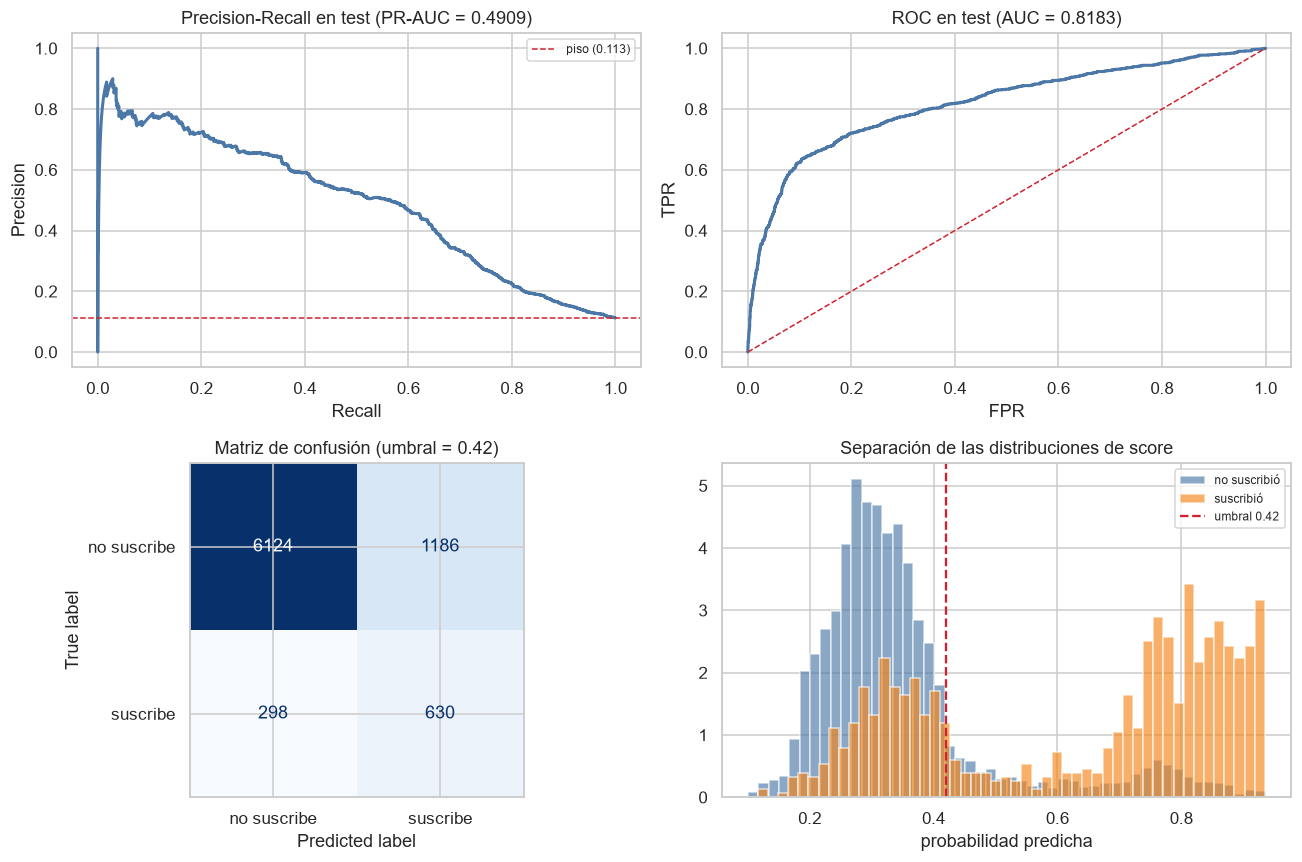

In [9]:
# Evaluación en test, con todos los gráficos.
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve
from src.data.split import load_splits
from src.models.evaluate import business_metrics, classification_metrics, lift_at_k

splits = load_splits()
test_proba = champion.model.predict_proba(splits.x_test)[:, 1]
threshold = champion.threshold

metrics = classification_metrics(splits.y_test, test_proba, threshold=threshold)
business = business_metrics(splits.y_test, test_proba, threshold=threshold)
lift = lift_at_k(splits.y_test, test_proba, config.business.call_capacity_fraction)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

precision, recall, _ = precision_recall_curve(splits.y_test, test_proba)
axes[0, 0].plot(recall, precision, color="#4c78a8", linewidth=2)
axes[0, 0].axhline(splits.y_test.mean(), color="#cf222e", linestyle="--", linewidth=1,
                   label=f"piso ({splits.y_test.mean():.3f})")
axes[0, 0].set_xlabel("Recall")
axes[0, 0].set_ylabel("Precision")
axes[0, 0].set_title(f"Precision-Recall en test (PR-AUC = {metrics['pr_auc']:.4f})")
axes[0, 0].legend(fontsize=8)

fpr, tpr, _ = roc_curve(splits.y_test, test_proba)
axes[0, 1].plot(fpr, tpr, color="#4c78a8", linewidth=2)
axes[0, 1].plot([0, 1], [0, 1], color="#cf222e", linestyle="--", linewidth=1)
axes[0, 1].set_xlabel("FPR")
axes[0, 1].set_ylabel("TPR")
axes[0, 1].set_title(f"ROC en test (AUC = {metrics['roc_auc']:.4f})")

ConfusionMatrixDisplay.from_predictions(
    splits.y_test, (test_proba >= threshold).astype(int),
    display_labels=["no suscribe", "suscribe"], cmap="Blues",
    colorbar=False, ax=axes[1, 0],
)
axes[1, 0].set_title(f"Matriz de confusión (umbral = {threshold:.2f})")

axes[1, 1].hist(test_proba[splits.y_test == 0], bins=50, alpha=0.65,
                label="no suscribió", color="#4c78a8", density=True)
axes[1, 1].hist(test_proba[splits.y_test == 1], bins=50, alpha=0.65,
                label="suscribió", color="#f58518", density=True)
axes[1, 1].axvline(threshold, color="#cf222e", linestyle="--", label=f"umbral {threshold:.2f}")
axes[1, 1].set_xlabel("probabilidad predicha")
axes[1, 1].set_title("Separación de las distribuciones de score")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [10]:
capacity = int(config.business.call_capacity_fraction * 100)
print("=" * 62)
print("RESULTADO EN TEST")
print("=" * 62)
print(f"  PR-AUC                  {metrics['pr_auc']:.4f}")
print(f"  ROC-AUC                 {metrics['roc_auc']:.4f}")
print(f"  Precision @ {threshold:.2f}        {metrics['precision']:.4f}")
print(f"  Recall @ {threshold:.2f}           {metrics['recall']:.4f}")
print(f"  Brier score             {metrics['brier_score']:.4f}")
print(f"  Lift top {capacity}%            {lift[f'top{capacity}_lift']:.2f}x")
print(f"  Recall top {capacity}%          {lift[f'top{capacity}_recall']:.3f}")
print()
print("IMPACTO DE NEGOCIO")
print(f"  Llamadas realizadas     {business['calls_made']:,} de {len(splits.y_test):,}")
print(f"  Suscripciones ganadas   {business['subscriptions_won']:,}")
print(f"  Suscripciones perdidas  {business['subscriptions_missed']:,}")
print(f"  Costo por adquisición   ${business['cost_per_acquisition_usd']:,.2f}")
print(f"  Utilidad del modelo     ${business['profit_usd']:,.0f}")
print(f"  Utilidad 'llamar a todos' ${business['profit_call_everyone_usd']:,.0f}")
print(f"  Ganancia incremental    ${business['profit_uplift_usd']:,.0f}")
print("=" * 62)

RESULTADO EN TEST
  PR-AUC                  0.4909
  ROC-AUC                 0.8183
  Precision @ 0.42        0.3469
  Recall @ 0.42           0.6789
  Brier score             0.1521
  Lift top 20%            3.31x
  Recall top 20%          0.663

IMPACTO DE NEGOCIO
  Llamadas realizadas     1,816 de 8,238
  Suscripciones ganadas   630
  Suscripciones perdidas  298
  Costo por adquisición   $23.06
  Utilidad del modelo     $35,872
  Utilidad 'llamar a todos' $8,336
  Ganancia incremental    $27,536


### Cómo leer la matriz de confusión

Los **falsos positivos** (llamadas que no convierten) son numerosos y eso es
*correcto*: cuestan $8 cada una, mientras cada suscripción aporta $80. El umbral
de 0,42 está calibrado para aceptar ese desperdicio a cambio de no perder
suscripciones.

El **Brier score** mide qué tan bien calibradas están las probabilidades. No se
aplicó calibración isotónica ni de Platt, así que los scores sirven para
**ordenar** clientes, no como estimaciones absolutas de riesgo. Está anotado
como limitación en la model card.

## 5. Importancia de features

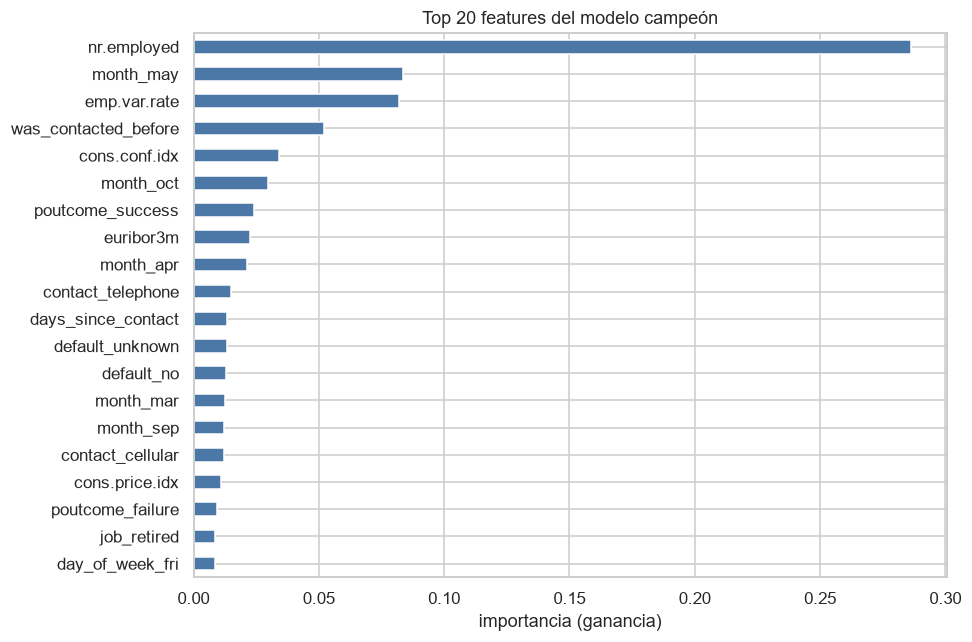

,importancia
nr.employed,0.2863
month_may,0.0836
emp.var.rate,0.0819
was_contacted_before,0.0522
cons.conf.idx,0.0341
month_oct,0.0297
poutcome_success,0.0240
euribor3m,0.0226
month_apr,0.0212
contact_telephone,0.0151


In [11]:
from src.features.preprocess import get_output_feature_names

classifier = champion.model.named_steps.get("classifier")
feature_names = get_output_feature_names(champion.model)

if classifier is not None and hasattr(classifier, "feature_importances_") and feature_names:
    importances = pd.Series(classifier.feature_importances_, index=feature_names)
    importances = importances.sort_values(ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(9, 6))
    importances.sort_values().plot.barh(ax=ax, color="#4c78a8")
    ax.set_xlabel("importancia (ganancia)")
    ax.set_title("Top 20 features del modelo campeón")
    plt.tight_layout()
    plt.show()

    display(importances.head(12).round(4).to_frame("importancia"))
else:
    print("El modelo campeón no expone importancia de features.")

### El hallazgo incómodo: el modelo es, en buena parte, un modelo macroeconómico

El resultado no es el que uno esperaría tras el EDA. Allí `poutcome` era la
variable con más poder discriminante por cliente; aquí **`nr.employed` domina la
importancia por un margen amplio**, seguida de `month_may`, `emp.var.rate` y
`cons.conf.idx`. `poutcome_success` aparece bastante más abajo.

Tres lecturas, en orden de importancia:

**1. El modelo apoya la mayor parte de su decisión en el contexto
macroeconómico, no en el perfil del cliente.** Esto confirma —y agrava— el
riesgo que anticipaba el EDA. En el periodo de entrenamiento (2008-2010) el
empleo y el euríbor se mueven junto con el éxito de las campañas, y el modelo
aprende esa co-ocurrencia. Es señal real y predictiva dentro de ese régimen, y
es exactamente lo que **deja de valer** cuando el régimen cambia.

Esto convierte al monitoreo de drift de `src/monitoring/drift.py` en algo que no
es decorativo: es la única defensa contra que el modelo siga prediciendo con
confianza a partir de un contexto económico que ya no existe. No es casualidad
que el escenario de drift simulado sea precisamente un cambio de régimen macro.

**2. La importancia está repartida de forma arbitraria entre variables
redundantes.** `euribor3m`, `nr.employed` y `emp.var.rate` correlacionan por
encima de 0,90 entre sí. Los árboles eligen una de ellas en cada split y las
demás quedan subvaloradas: que `nr.employed` aparezca con 0,29 y `euribor3m` con
0,02 **no** significa que la primera importe quince veces más. Significa que
capturan lo mismo y el modelo se queda con la primera que encuentra. De aquí no
se puede leer causalidad.

**3. El feature engineering sí aportó.** `was_contacted_before` —una de las dos
features derivadas de `pdays`— aparece entre las primeras, lo que valida la
decisión tomada en el EDA de descomponer el centinela 999 en vez de dejarlo
como número.

`month_may` en segundo lugar merece la misma advertencia que en el EDA: no es
estacionalidad, es el calendario de campañas del banco. Si la operación cambia
su calendario, esa feature se vuelve engañosa.

## 6. Estado del Model Registry

In [12]:
versions = client.search_model_versions(f"name = '{config.mlflow.registered_model_name}'")

registry_rows = []
for version in versions:
    registry_rows.append(
        {
            "versión": version.version,
            "alias": ", ".join(version.aliases) if version.aliases else "—",
            "familia": version.tags.get("model_family", "—"),
            "test PR-AUC": version.tags.get("test_pr_auc", "—"),
            "umbral": version.tags.get("decision_threshold", "—"),
            "registrada": version.tags.get("trained_at", "—"),
        }
    )

registry_table = pd.DataFrame(registry_rows).sort_values("versión", ascending=False)
display(registry_table.reset_index(drop=True))

print(f"\nEl alias '{config.mlflow.champion_alias}' apunta a la versión {champion.version}.")
print("La API y el batch scoring piden `models:/<nombre>@champion`, así que")
print("mover el alias cambia el modelo servido sin tocar una línea de código.")

,versión,alias,familia,test PR-AUC,umbral,registrada
0,1,—,xgboost_tuned,0.49095,0.42,2026-10-12T20:14:34



El alias 'champion' apunta a la versión 1.
La API y el batch scoring piden `models:/<nombre>@champion`, así que
mover el alias cambia el modelo servido sin tocar una línea de código.


## Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo ganó? | XGBoost con hiperparámetros de Optuna |
| ¿Cuánto mejor que el baseline? | ~4x el piso de la tasa base; un dígito bajo por encima de la regresión logística |
| ¿Es estable? | Sí: la CV de 5 folds concuerda con validation |
| ¿Valió la pena el tuning? | Poco; el grueso del valor vino del feature engineering y del umbral |
| ¿De qué depende el modelo? | Sobre todo de variables macroeconómicas, no del perfil del cliente |
| ¿Qué limita el modelo? | Esa dependencia macro (riesgo de deriva) y probabilidades sin calibrar |

**Documentación generada por el pipeline:**

* `models/model_card.md` — uso previsto, desempeño y limitaciones
* `reports/drift_report_latest.html` — estado del monitoreo
* `docs/monitoring.md` — diseño del monitoreo en producción